# Heyert Notebook
### 2026-11
### Text Corpus Exploration | Project 03 | NLP

Exploratory analysis of job application messages using token frequencies, category comparisons, immediate-neighbor co-occurrences, and bigrams.

**Data requirement:** Place your csv corpus in the project's local `data/` directory. The data directory is excluded from version control, for privacy reasons, and this notebook does not embed the dataset. This pipeline should be adaptable to any CSV with a category column and a text column.

## 1. Imports and project paths

The project root is found by locating `pyproject.toml` in the current directory or one of the parents to resolve common path errors in Jupyter Notebooks.

In [328]:
from pathlib import Path

from IPython.display import display  # Fix linting issues
import matplotlib.pyplot as plt
import polars as pl

project_root = next(
    (
        path
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "pyproject.toml").is_file()
    ),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "Could not find the project root (pyproject.toml) from the current directory."
    )

data_file = project_root / "data" / "job_messages.csv"
if not data_file.is_file():
    raise FileNotFoundError(
        f"Dataset not found: {data_file}. Add job_messages.csv to the project's data/ directory."
    )

print(f"Project root: {project_root}")
print(f"Dataset: {data_file}")
# Define the output path for saving figures
PLOT_PATH = project_root / "docs/images"
print(f"Plot path: {PLOT_PATH}")
ARTIFACT_PATH: Path = project_root / "artifacts"
print(f"Artifact path: {ARTIFACT_PATH}")

Project root: c:\Repos\nlp-03-text-exploration-context
Dataset: c:\Repos\nlp-03-text-exploration-context\data\job_messages.csv
Plot path: c:\Repos\nlp-03-text-exploration-context\docs\images
Artifact path: c:\Repos\nlp-03-text-exploration-context\artifacts


## 2. Load the corpus

Each row is treated as a document with a category and message text. The summary below reports dataset structure without displaying message contents.

In [329]:
df_corpus: pl.DataFrame = pl.read_csv(
    data_file, columns=["category", "text"]
).with_row_index("message_id")

print(f"Corpus contains {df_corpus.height} documents.")
print("Documents by category:")
display(df_corpus.group_by("category").len().sort("category"))

Corpus contains 202 documents.
Documents by category:


category,len
str,u64
"""application_received""",115
"""application_update""",5
"""interview_stage""",27
"""job_offer""",5
"""process_update""",16
"""rejected""",34


## 3. Tokenize and clean text

This simple tokenizer lowercases text, splits on whitespace, removes every character that is not a Unicode letter or number, and excludes tokens of two characters or fewer. For example, `don't` becomes `dont`, and `job-related` becomes `jobrelated` because punctuation is removed rather than replaced with a space. `token_df` contains all resulting tokens. `filtered_df` is a copy with the words in `stop_words` removed.

### Where stop-word filtering is used

- Overall and per-category token-frequency tables use `filtered_df`, so they omit the words listed in `stop_words`.
- Co-occurrence and bigram analyses use `token_df` and count the cleaned tokens as they appear in each message.

Filtering happens after tokenization. It does not change the token sequence used to calculate contexts or bigrams.

In [330]:
token_df: pl.DataFrame = (
    df_corpus.select(
        "message_id",
        "category",
        pl.col("text")
        .str.to_lowercase()
        .str.replace_all(r"\s+", " ")
        .str.strip_chars()
        .str.split(" ")
        .alias("token"),
    )
    .explode("token")
    .with_columns(pl.col("token").str.replace_all(r"[^\p{L}\p{N}]", "").alias("token"))
    .filter(pl.col("token") != "")
    .filter(pl.col("token").str.len_chars() > 2)
    .with_columns(pl.int_range(pl.len()).over("message_id").alias("position"))
    .sort(["message_id", "position"])
)

print(f"Tokenization produced {token_df.height} tokens.")
display(token_df.head(10))

Tokenization produced 19782 tokens.


message_id,category,token,position
u64,str,str,i64
0,"""application_received""","""thank""",0
0,"""application_received""","""you""",1
0,"""application_received""","""for""",2
0,"""application_received""","""your""",3
0,"""application_received""","""interest""",4
0,"""application_received""","""career""",5
0,"""application_received""","""oracle""",6
0,"""application_received""","""appreciate""",7
0,"""application_received""","""you""",8


In [331]:
stop_words = [
    "the",
    "a",
    "an",
    "and",
    "or",
    "but",
    "in",
    "on",
    "at",
    "to",
    "for",
    "of",
    "with",
    "by",
    "is",
    "are",
    "was",
    "were",
    "be",
    "been",
    "being",
    "have",
    "has",
    "had",
    "do",
    "does",
    "did",
    "will",
    "would",
    "can",
    "could",
    "should",
    "may",
    "might",
    "must",
    "shall",
    "your",
    "you",
]
filtered_df = token_df.filter(~pl.col("token").is_in(stop_words))
# Show the filtered DataFrame
display(filtered_df.head(5))

message_id,category,token,position
u64,str,str,i64
0,"""application_received""","""thank""",0
0,"""application_received""","""interest""",4
0,"""application_received""","""career""",5
0,"""application_received""","""oracle""",6
0,"""application_received""","""appreciate""",7


## 4. Most frequent tokens

Count each token across the corpus after removing the words listed in `stop_words`.

In [332]:
global_freq_df: pl.DataFrame = (
    filtered_df.group_by("token").len().sort("len", descending=True)
)
display(global_freq_df.head(10))

token,len
str,u64
"""our""",319
"""application""",275
"""this""",258
"""thank""",218
"""that""",169
"""team""",155
"""please""",147
"""interest""",146
"""position""",145


## 5. Most frequent tokens per category

The table counts cleaned tokens separately for each category. The chart below shows the ten most frequent tokens in each one.

In [333]:
category_freq_df: pl.DataFrame = (
    filtered_df.group_by(["category", "token"])
    .len()
    .sort(["category", "len", "token"], descending=[False, True, False])
)
display(category_freq_df[:10])

category,token,len
str,str,u64
"""application_received""","""our""",233
"""application_received""","""application""",203
"""application_received""","""thank""",128
"""application_received""","""this""",118
"""application_received""","""team""",101
"""application_received""","""that""",86
"""application_received""","""email""",84
"""application_received""","""position""",82
"""application_received""","""interest""",75


### Category token frequency chart

Each panel shows the ten most frequent tokens in that category after removing the words listed in `stop_words`.

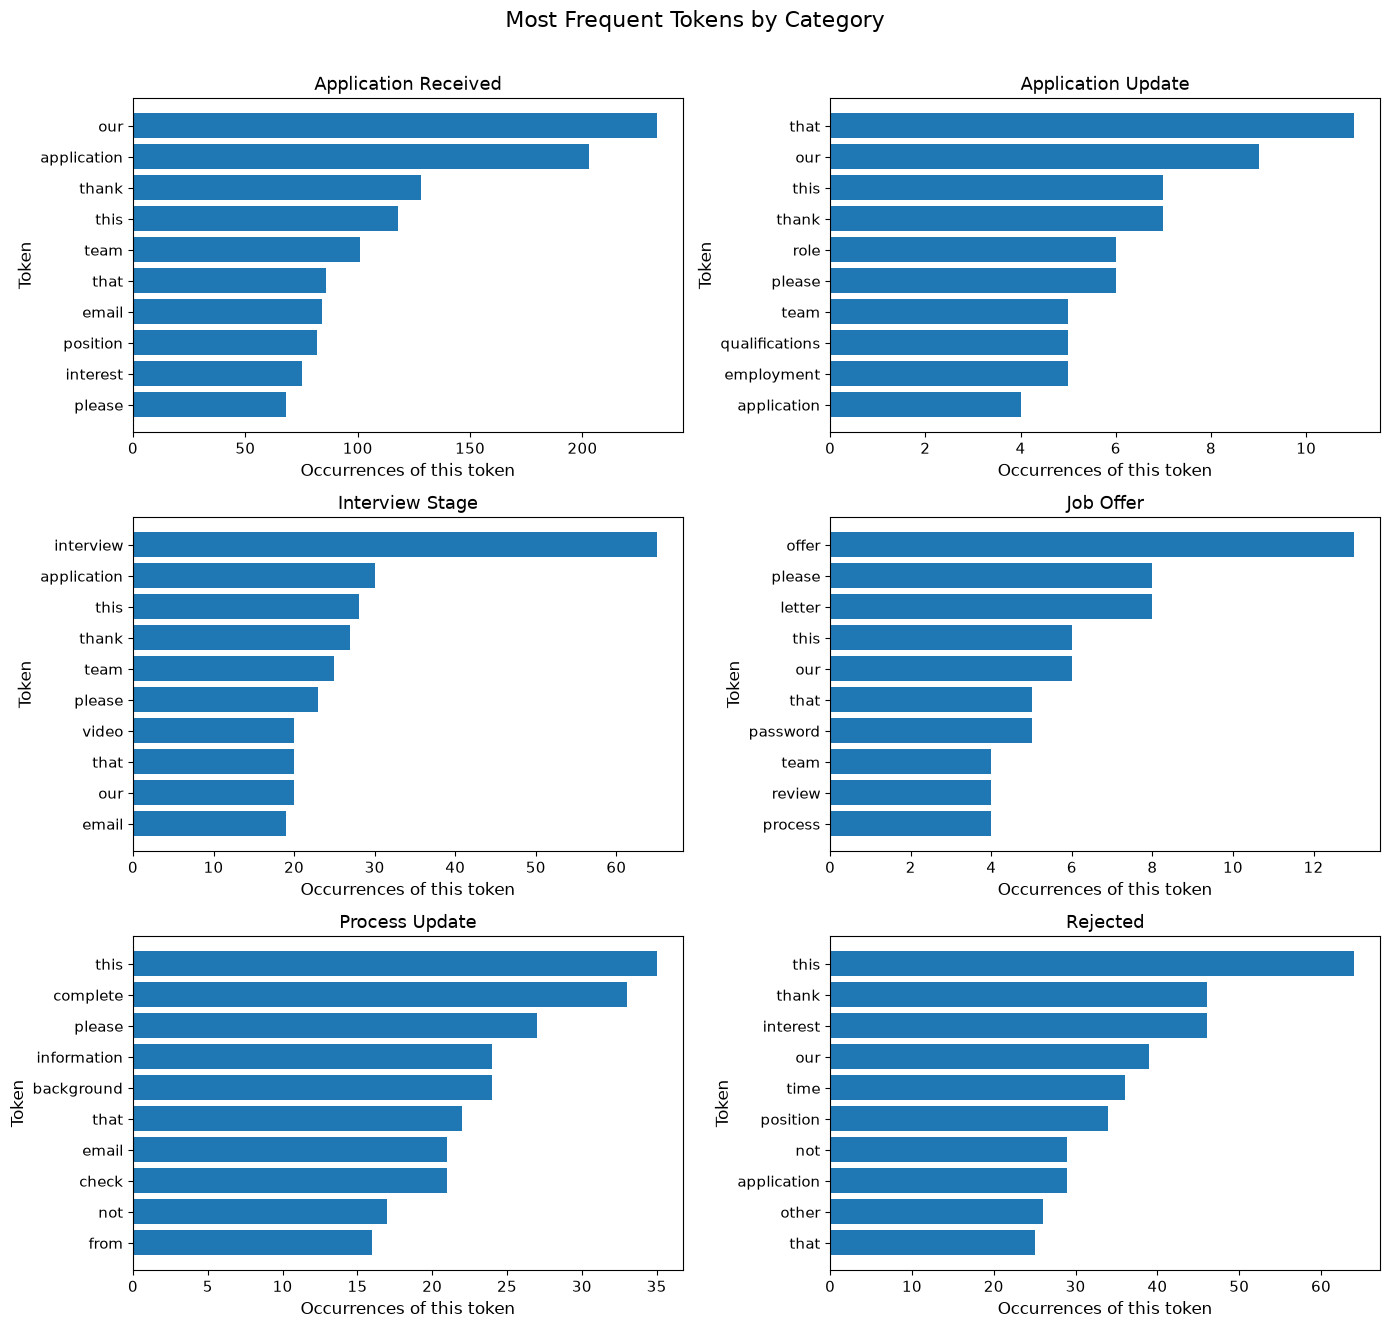

In [334]:
categories = category_freq_df["category"].unique().sort().to_list()
columns = 2
rows = (len(categories) + columns - 1) // columns
fig, axes = plt.subplots(rows, columns, figsize=(14, 4.5 * rows), squeeze=False)
for ax, category in zip(axes.flat, categories):
    plot_df = (
        category_freq_df.filter(pl.col("category") == category).head(10).sort("len")
    )
    ax.barh(plot_df["token"].to_list(), plot_df["len"].to_list())
    ax.set_title(category.replace("_", " ").title(), fontsize=13)
    ax.set_xlabel("Occurrences of this token", fontsize=12)
    ax.set_ylabel("Token", fontsize=12)
    ax.tick_params(labelsize=11)
for ax in axes.flat[len(categories) :]:
    ax.set_visible(False)
fig.suptitle("Most Frequent Tokens by Category", fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.savefig(PLOT_PATH / "tokens_by_category.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Immediate-neighbor co-occurrences

A word co-occurs with another when it appears immediately before or after it in the same message. The tables count neighboring words as they appear in the messages and show the most frequent pairs overall and by category.


In [335]:
context_df = pl.concat(
    [
        token_df.select(
            "category",
            pl.col("token").alias("target_token"),
            pl.col("token").shift(offset).over("message_id").alias("context_token"),
        )
        for offset in [-1, 1]
    ]
).filter(
    pl.col("context_token").is_not_null()
    & (pl.col("target_token") != pl.col("context_token"))
)

co_occurrence_df = (
    context_df.group_by(["target_token", "context_token"])
    .len()
    .sort("len", descending=True)
)
display(co_occurrence_df.sort("len", descending=True).head(10))

co_occurrence_by_category_df = context_df.group_by(
    ["category", "target_token", "context_token"]
).len()
display(co_occurrence_by_category_df.sort("len", descending=True).head(10))

target_token,context_token,len
str,str,u64
"""thank""","""you""",221
"""you""","""thank""",221
"""application""","""your""",201
"""your""","""application""",201
"""you""","""for""",178
"""for""","""you""",178
"""your""","""for""",136
"""for""","""your""",136
"""interest""","""your""",132


category,target_token,context_token,len
str,str,str,u64
"""application_received""","""application""","""your""",146
"""application_received""","""your""","""application""",146
"""application_received""","""you""","""thank""",129
"""application_received""","""thank""","""you""",129
"""application_received""","""for""","""you""",106
"""application_received""","""you""","""for""",106
"""application_received""","""for""","""your""",74
"""application_received""","""your""","""for""",74
"""application_received""","""your""","""interest""",71


## 7. Most common bigrams

A bigram is a pair of consecutive tokens from the same message. The token table is already sorted by message and position, so a grouped `shift(-1)` selects the next word without crossing message boundaries. Each pair is counted as it appears in the message.


In [336]:
bigram_df: pl.DataFrame = (
    token_df.with_columns(
        pl.col("token").shift(-1).over("message_id").alias("next_token")
    )
    .filter(pl.col("next_token").is_not_null())
    .with_columns(pl.concat_str(["token", "next_token"], separator=" ").alias("bigram"))
    .select("message_id", "category", "bigram")
)

display(bigram_df.group_by("bigram").len().sort("len", descending=True).head(10))

bigram,len
str,u64
"""thank you""",218
"""your application""",196
"""you for""",160
"""for your""",136
"""your interest""",132
"""for the""",105
"""this email""",71
"""you can""",61
"""application for""",54


## 8. Most common bigrams by category

Each panel shows the ten most frequent consecutive-token pairs in that category.

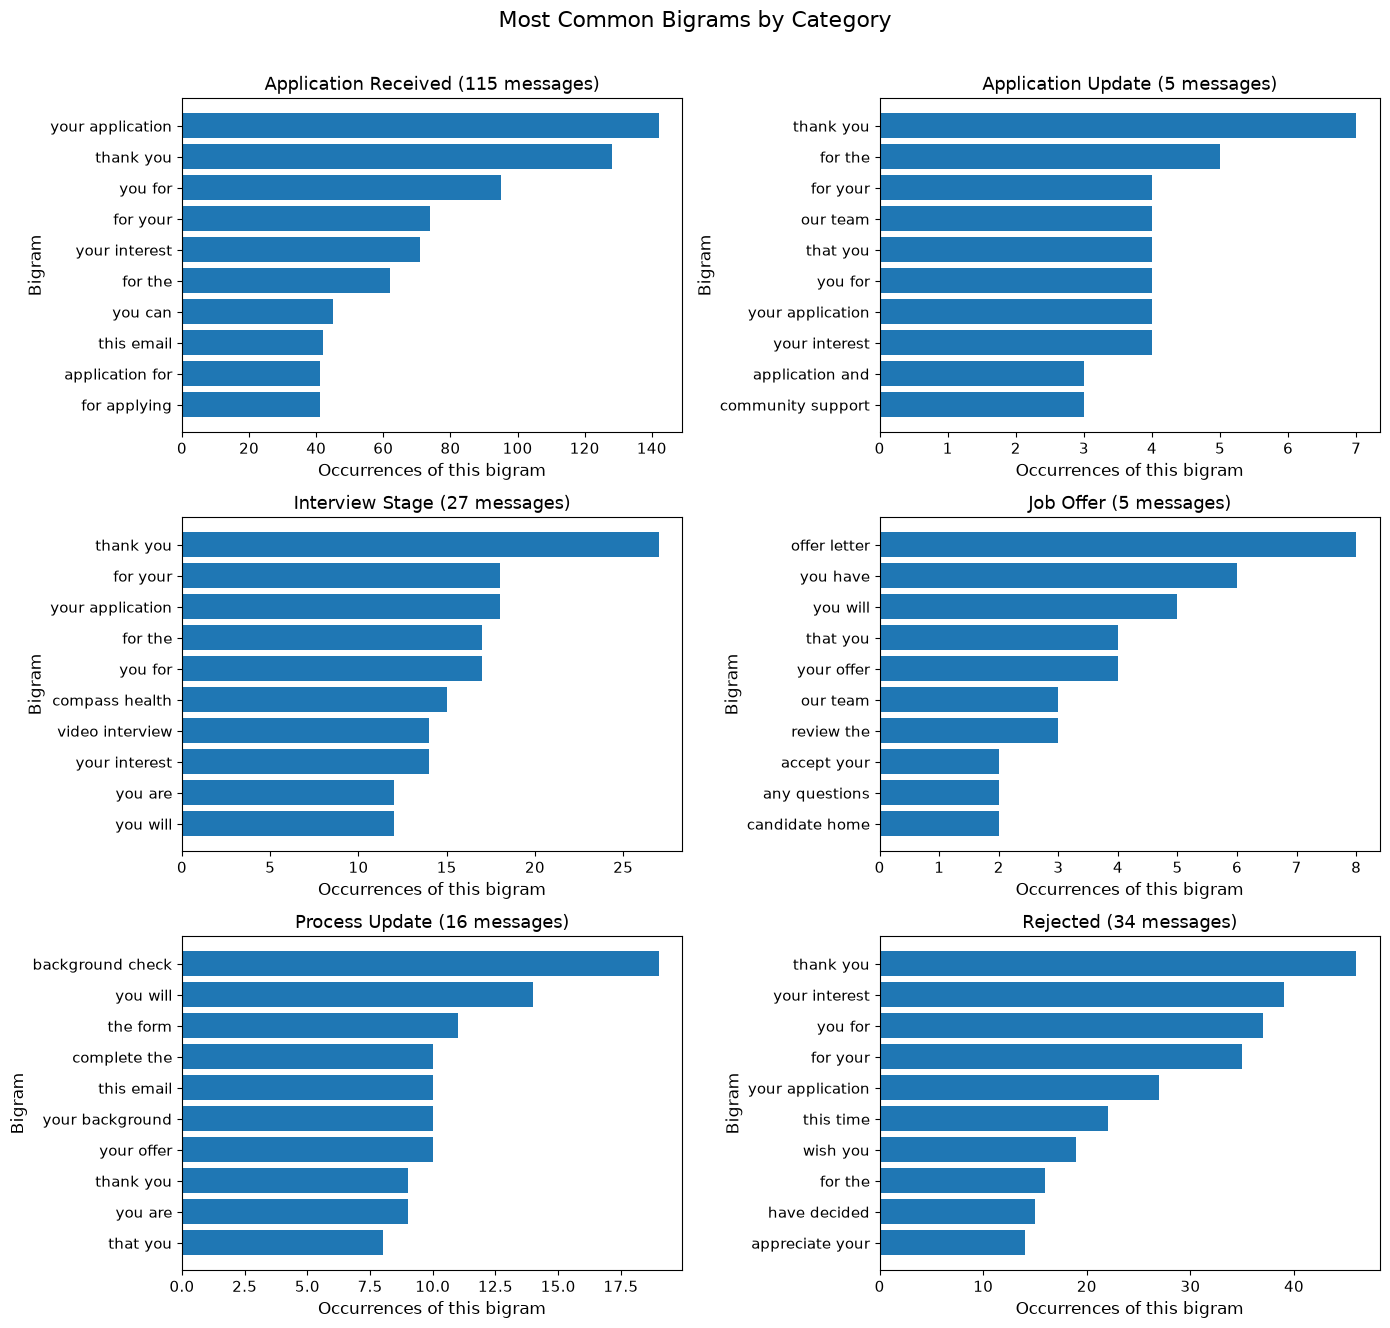

In [337]:
categories = bigram_df["category"].unique().sort().to_list()
columns = 2
rows = (len(categories) + columns - 1) // columns
fig, axes = plt.subplots(rows, columns, figsize=(14, 4.5 * rows), squeeze=False)
for ax, category in zip(axes.flat, categories):
    plot_df = (
        bigram_df.filter(pl.col("category") == category)
        .group_by("bigram")
        .len()
        .sort(["len", "bigram"], descending=[True, False])
        .head(10)
        .sort("len")
    )
    ax.barh(plot_df["bigram"].to_list(), plot_df["len"].to_list())
    number_of_messages = df_corpus.filter(pl.col("category") == category).height
    ax.set_title(
        f"{category.replace('_', ' ').title()} ({number_of_messages} messages)",
        fontsize=13,
    )
    ax.set_xlabel("Occurrences of this bigram", fontsize=12)
    ax.set_ylabel("Bigram", fontsize=12)
    ax.tick_params(labelsize=11)
for ax in axes.flat[len(categories) :]:
    ax.set_visible(False)
fig.suptitle("Most Common Bigrams by Category", fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.savefig(PLOT_PATH / "bigram_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

## 9. Most common trigrams

A trigram is a sequence of three consecutive tokens from the same message. Each sequence is counted as it appears in the message.

In [338]:
trigram_df: pl.DataFrame = (
    token_df.with_columns(
        pl.col("token").shift(-1).over("message_id").alias("next_token"),
        pl.col("token").shift(-2).over("message_id").alias("third_token"),
    )
    .filter(pl.col("third_token").is_not_null())
    .with_columns(
        pl.concat_str(["token", "next_token", "third_token"], separator=" ").alias(
            "trigram"
        )
    )
    .select("message_id", "category", "trigram")
)

display(trigram_df.group_by("trigram").len().sort("len", descending=True).head(10))

trigram,len
str,u64
"""thank you for""",149
"""for your interest""",95
"""you for your""",85
"""your application for""",52
"""you for applying""",40
"""received your application""",39
"""will contact you""",38
"""learn more about""",36
"""your interest joining""",32


## 10. Most common trigrams by category

Each panel shows the ten most frequent consecutive three-token sequences in that category.

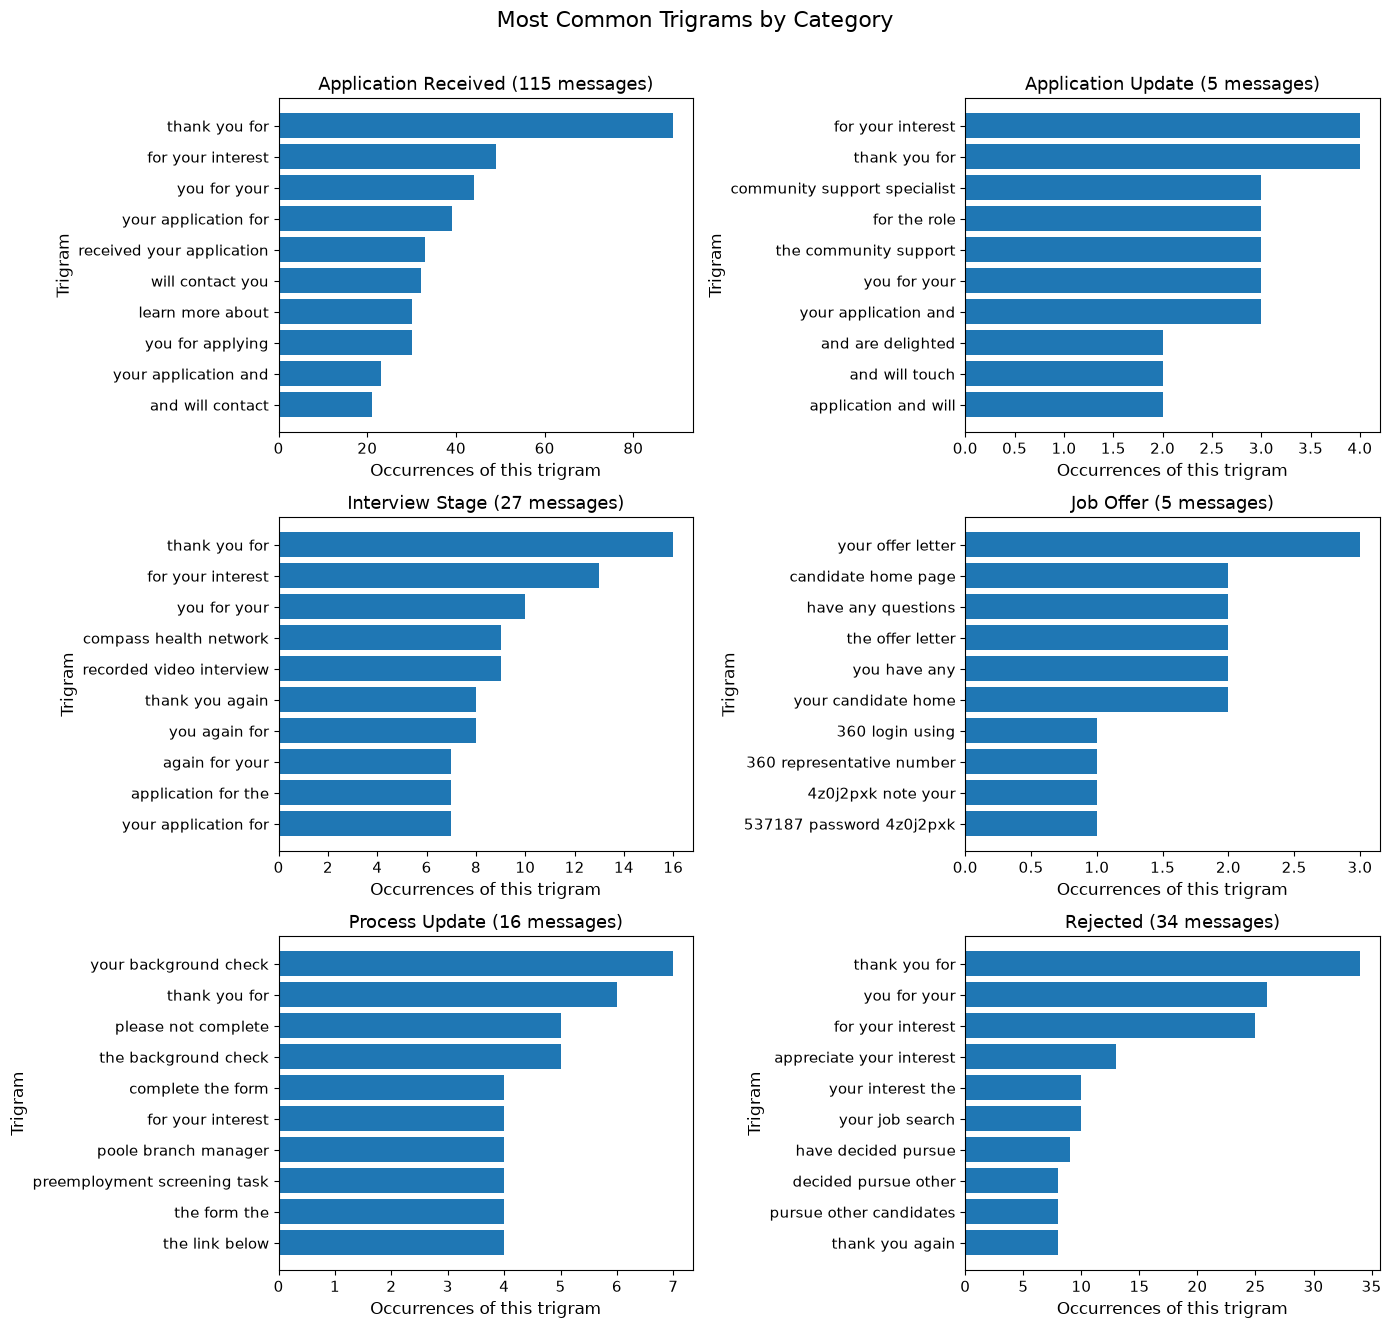

In [339]:
categories = trigram_df["category"].unique().sort().to_list()
columns = 2
rows = (len(categories) + columns - 1) // columns
fig, axes = plt.subplots(rows, columns, figsize=(14, 4.5 * rows), squeeze=False)
for ax, category in zip(axes.flat, categories):
    plot_df = (
        trigram_df.filter(pl.col("category") == category)
        .group_by("trigram")
        .len()
        .sort(["len", "trigram"], descending=[True, False])
        .head(10)
        .sort("len")
    )
    ax.barh(plot_df["trigram"].to_list(), plot_df["len"].to_list())
    number_of_messages = df_corpus.filter(pl.col("category") == category).height
    ax.set_title(
        f"{category.replace('_', ' ').title()} ({number_of_messages} messages)",
        fontsize=13,
    )
    ax.set_xlabel("Occurrences of this trigram", fontsize=12)
    ax.set_ylabel("Trigram", fontsize=12)
    ax.tick_params(labelsize=11)
for ax in axes.flat[len(categories) :]:
    ax.set_visible(False)
fig.suptitle("Most Common Trigrams by Category", fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.savefig(PLOT_PATH / "trigram_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

## 11. Comparing shared and category-specific language

This summary measures how often the same bigram or trigram appears across categories. The phrase table checks examples associated with process updates and rejections. These are descriptive counts; categories have different numbers of messages, so the phrase table also shows the percentage of each category's messages that contain a phrase. Application updates and job offers have only five messages each, so their percentages are especially sensitive to individual messages.

The tokenizer removes tokens of two characters or fewer. For example, an original phrase like `decided to pursue` appears as `decided pursue` in this analysis.

In [ ]:
number_of_categories = df_corpus["category"].n_unique()

# Put bigrams and trigrams in one table so the same metrics apply to both.
ngram_rows_df = pl.concat(
    [
        bigram_df.select(
            pl.lit("Bigram").alias("type"),
            pl.col("bigram").alias("ngram"),
            "category",
            "message_id",
        ),
        trigram_df.select(
            pl.lit("Trigram").alias("type"),
            pl.col("trigram").alias("ngram"),
            "category",
            "message_id",
        ),
    ]
)

phrase_stats_df = ngram_rows_df.group_by(["type", "ngram"]).agg(
    pl.col("category").n_unique().alias("category_count"),
    pl.len().alias("occurrences"),
    pl.col("message_id").n_unique().alias("messages"),
    pl.col("category").unique().sort().alias("categories"),
)

# Separate phrase overlap from how often those phrases occur.
ngram_summary_df = (
    phrase_stats_df.group_by("type")
    .agg(
        pl.len().alias("distinct phrases"),
        (pl.col("category_count") >= 2).sum().alias("shared phrases"),
        ((pl.col("category_count") >= 2).mean() * 100)
        .round(1)
        .alias("shared phrase types (%)"),
        (
            pl.when(pl.col("category_count") >= 2)
            .then(pl.col("occurrences"))
            .otherwise(0)
            .sum()
            / pl.col("occurrences").sum()
            * 100
        )
        .round(1)
        .alias("occurrences from shared phrases (%)"),
        (pl.col("category_count") == number_of_categories)
        .sum()
        .alias("phrases in every category"),
    )
    .sort("type")
)
display(ngram_summary_df)

# Show the most frequent phrases overall and which categories use them.
top_ngrams_df = (
    phrase_stats_df.sort(
        ["type", "occurrences", "ngram"], descending=[False, True, False]
    )
    .group_by("type", maintain_order=True)
    .head(5)
    .select("type", "ngram", "occurrences", "messages", "category_count", "categories")
)
display(top_ngrams_df)

# Rank phrases used in only one category; hide credential-like text in examples.
category_sizes_df = (
    df_corpus.group_by("category").len().rename({"len": "total_messages"})
)
category_exclusive_df = (
    ngram_rows_df.group_by(["type", "category", "ngram"])
    .agg(
        pl.len().alias("occurrences"),
        pl.col("message_id").n_unique().alias("messages"),
    )
    .join(
        phrase_stats_df.filter(pl.col("category_count") == 1).select("type", "ngram"),
        on=["type", "ngram"],
    )
    .filter(
        ~pl.col("ngram").str.contains(
            r"(?i)\b(password|passcode|login|verification|pin|code)\b|\d"
        )
    )
    .join(category_sizes_df, on="category")
    .with_columns(
        (pl.col("messages") / pl.col("total_messages") * 100)
        .round(1)
        .alias("messages (%)")
    )
    .sort(
        ["type", "category", "occurrences", "ngram"],
        descending=[False, False, True, False],
    )
    .group_by(["type", "category"], maintain_order=True)
    .head(3)
    .select(
        "type",
        "category",
        "ngram",
        "occurrences",
        "messages",
        "total_messages",
        "messages (%)",
    )
)
category_exclusive_examples_df = (
    category_exclusive_df.with_columns(
        pl.concat_str(
            [
                "ngram",
                pl.lit(" ("),
                pl.col("occurrences").cast(pl.String),
                pl.lit(" occurrences, "),
                pl.col("messages (%)").cast(pl.String),
                pl.lit("% of messages)"),
            ]
        ).alias("example")
    )
    .group_by(["type", "category"], maintain_order=True)
    .agg(pl.col("example").str.join("; ").alias("top exclusive phrases"))
)
with pl.Config(fmt_str_lengths=120):
    display(category_exclusive_examples_df.filter(pl.col("type") == "Bigram"))
    display(category_exclusive_examples_df.filter(pl.col("type") == "Trigram"))

# Count selected phrases by category to check the examples discussed below.
phrase_counts_df = (
    ngram_rows_df.filter(
        pl.col("ngram").is_in(
            [
                "background check",
                "your interest",
                "decided pursue",
                "your background check",
                "for your interest",
                "have decided pursue",
            ]
        )
    )
    .group_by(["type", "ngram", "category"])
    .agg(
        pl.len().alias("occurrences"),
        pl.col("message_id").n_unique().alias("messages"),
    )
    .join(category_sizes_df, on="category")
    .with_columns(
        (pl.col("messages") / pl.col("total_messages") * 100)
        .round(1)
        .alias("messages (%)")
    )
    .sort(["type", "ngram", "category"])
)
display(phrase_counts_df)

type,distinct phrases,shared phrases,shared phrase types (%),occurrences from shared phrases (%),phrases in every category
str,u64,u64,f64,f64,u64
"""Bigram""",8724,1206,13.8,44.3,10
"""Trigram""",11805,792,6.7,21.5,1


type,ngram,occurrences,messages,category_count,categories
str,str,u64,u64,u64,list[str]
"""Bigram""","""thank you""",218,154,6,"[""application_received"", ""application_update"", … ""rejected""]"
"""Bigram""","""your application""",196,120,5,"[""application_received"", ""application_update"", … ""rejected""]"
"""Bigram""","""you for""",160,138,6,"[""application_received"", ""application_update"", … ""rejected""]"
"""Bigram""","""for your""",136,105,5,"[""application_received"", ""application_update"", … ""rejected""]"
"""Bigram""","""your interest""",132,97,5,"[""application_received"", ""application_update"", … ""rejected""]"
"""Trigram""","""thank you for""",149,134,5,"[""application_received"", ""application_update"", … ""rejected""]"
"""Trigram""","""for your interest""",95,78,5,"[""application_received"", ""application_update"", … ""rejected""]"
"""Trigram""","""you for your""",85,80,5,"[""application_received"", ""application_update"", … ""rejected""]"
"""Trigram""","""your application for""",52,50,5,"[""application_received"", ""application_update"", … ""rejected""]"


type,category,top exclusive phrases
str,str,str
"""Bigram""","""application_received""","""you want (13 occurrences, 9.6% of messages); about our (12 occurrences, 10.4% of messages); can also (12 occurrences, 7.…"
"""Bigram""","""application_update""","""are delighted (2 occurrences, 40.0% of messages); can you (2 occurrences, 20.0% of messages); considered qualifying (2 o…"
"""Bigram""","""interview_stage""","""video interview (14 occurrences, 33.3% of messages); recorded video (9 occurrences, 14.8% of messages); audio and (7 occ…"
"""Bigram""","""job_offer""","""the details (2 occurrences, 40.0% of messages); the offer (2 occurrences, 40.0% of messages); the premium (2 occurrences…"
"""Bigram""","""process_update""","""background check (19 occurrences, 31.2% of messages); the form (11 occurrences, 18.8% of messages); adecco usa (7 occurr…"
"""Bigram""","""rejected""","""other candidates (14 occurrences, 41.2% of messages); continue explore (5 occurrences, 14.7% of messages); for new (5 oc…"


type,category,top exclusive phrases
str,str,str
"""Trigram""","""application_received""","""join our talent (15 occurrences, 7.0% of messages); with next steps (12 occurrences, 10.4% of messages); you can also (1…"
"""Trigram""","""application_update""","""and are delighted (2 occurrences, 40.0% of messages); are delighted that (2 occurrences, 40.0% of messages); can you ple…"
"""Trigram""","""interview_stage""","""recorded video interview (9 occurrences, 14.8% of messages); like invite you (5 occurrences, 18.5% of messages); selecte…"
"""Trigram""","""job_offer""","""the offer letter (2 occurrences, 40.0% of messages); aba rbt offer (1 occurrences, 20.0% of messages); able review the (…"
"""Trigram""","""process_update""","""your background check (7 occurrences, 18.8% of messages); please not complete (5 occurrences, 18.8% of messages); the ba…"
"""Trigram""","""rejected""","""pursue other candidates (8 occurrences, 23.5% of messages); with other candidates (5 occurrences, 14.7% of messages); af…"


type,ngram,category,occurrences,messages,total_messages,messages (%)
str,str,str,u64,u64,u64,f64
"""Bigram""","""background check""","""process_update""",19,5,16,31.2
"""Bigram""","""decided pursue""","""application_received""",2,2,115,1.7
"""Bigram""","""decided pursue""","""rejected""",9,9,34,26.5
"""Bigram""","""your interest""","""application_received""",71,61,115,53.0
"""Bigram""","""your interest""","""application_update""",4,3,5,60.0
…,…,…,…,…,…,…
"""Trigram""","""for your interest""","""process_update""",4,3,16,18.8
"""Trigram""","""for your interest""","""rejected""",25,19,34,55.9
"""Trigram""","""have decided pursue""","""application_received""",2,2,115,1.7


### Interpretation of results

A lot of the messages use familiar recruiting language. The most common bigram is `thank you` (218 occurrences in all six categories), and the most common trigram is `thank you for` (149 occurrences in five categories). Other frequent phrases are `your application` (196), `your interest` (132), and `for your interest` (95). The table above shows the categories where each phrase appears.

The percentages describe repeated phrases: 13.8% of different bigrams and 6.7% of different trigrams appear in more than one category. Those repeated phrases account for 44.3% of all bigram uses and 21.5% of all trigram uses. So most phrase types differ, but a smaller set of common phrases appears again and again. The tables above give examples, rather than leaving this conclusion to the graphs alone.

Some phrases do stand out by category. In process updates, `background check` appears 19 times across five messages, and `your background check` appears in three messages. In rejections, `decided pursue` appears in nine messages, and `pursue other candidates` appears in eight. These are counted per message in the table so repeated use in one email is not mistaken for several separate emails. The top-phrases-by-category table also shows interview language such as `video interview` and offer language such as `the offer letter`.

`your interest` appears in 23 rejection messages (67.6%), but it also appears in 61 application-received messages (53.0%). That makes it sound like common recruiting wording, not something specific to rejections. The category labels broadly match my experience. I estimate around 400 other applications never acknowledged my submission, but that is my estimate, not something this dataset can measure. I left third-party websites out to avoid counting repeated messages.